# Kaggriculture Daily Replays: The Live Meta Report

*By [Georgy Mamarin](https://www.kaggle.com/georgymamarin)*

Every finished game on the [Kaggriculture](https://www.kaggle.com/competitions/kaggriculture)
ladder leaves a full public replay: 720 turns, both players, every observation and every action.
I collect them into the
[Kaggriculture Episodes](https://www.kaggle.com/datasets/georgymamarin/kaggriculture-episodes)
dataset, and this notebook is the live look inside: what the data holds today, and what the
leading farms measurably do differently.

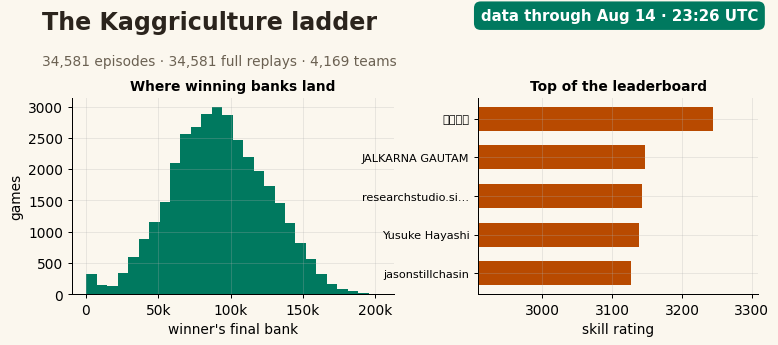

pandas 2.3.3 · numpy 2.0.2 · executed 2026-08-15 23:22 UTC · full run ~1 min


*Fresh: newest recorded game ended Aug 14, 23:26 UTC, 24h before this run.*

In [1]:
# Reads the dataset in place: on Kaggle from /kaggle/input, locally from the staging copy.
import gc, glob, json, os, textwrap, warnings
from datetime import timezone

# DejaVu, matplotlib's default font, has no CJK glyphs: a Japanese team name prints a
# warning per glyph and draws as boxes. The names fall back below; the warning goes here.
warnings.filterwarnings("ignore", message="Glyph")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.dataset as pads
from IPython.display import Markdown, display

hits = (glob.glob("/kaggle/input/**/episodes.csv", recursive=True)
        + glob.glob("../episodes_dataset/episodes.csv")
        + glob.glob("../../episodes_dataset/episodes.csv"))
if not hits:
    raise FileNotFoundError("episodes.csv not found — attach the kaggriculture-episodes dataset")
BASE = os.path.dirname(hits[0])

eps = pd.read_csv(f"{BASE}/episodes.csv")
agents = pd.read_csv(f"{BASE}/agents.csv")
try:                                                      # ids are unreadable on charts
    teams = pd.read_csv(f"{BASE}/teams.csv")
except FileNotFoundError:                                 # older dataset version
    teams = pd.DataFrame(columns=["team_id", "team_name", "ladder_score", "last_submission"])
NAME = dict(zip(teams.team_id, teams.team_name))
def name_of(tid):
    # Chart-safe names: Latin and Cyrillic render everywhere, anything past that
    # (CJK and friends) becomes "team <id>" instead of tofu boxes on the axis.
    n = NAME.get(tid, f"team {tid}")
    return n if all(ord(ch) <= 0x04FF for ch in str(n)) else f"team {tid}"
# Which episodes have a replay: read it from the 1 MB features table when present.
# Scanning that column out of replays.parquet costs seconds today and minutes once the
# corpus is a few GB, so the cheap source wins as the dataset grows.
try:
    feats = pd.read_csv(f"{BASE}/episode_features.csv", usecols=["episode_id"])
    replay_ids = set(feats.episode_id)
except (FileNotFoundError, ValueError):
    replay_ids = set(pd.read_parquet(f"{BASE}/replays.parquet",
                                     columns=["episode_id"]).episode_id)

def load_replay(episode_id):
    # A row group here holds 20 replays and decompresses to ~260 MB, so
    # read_parquet(filters=...) pulls the whole group into memory for one row and
    # killed the kernel once the corpus passed 800 MB (2026-08-08). Scanning with
    # batch_size=1 keeps the working set at a single replay.
    scanner = pads.dataset(f"{BASE}/replays.parquet", format="parquet").scanner(
        filter=pads.field("episode_id") == int(episode_id),
        columns=["replay_json"], batch_size=1)
    blob = scanner.head(1).column("replay_json")[0].as_py()
    del scanner
    gc.collect()
    out = json.loads(blob)
    del blob
    gc.collect()
    return out

eps["has_replay"] = eps.episode_id.isin(replay_ids)
eps["winner_bank"] = eps[["bank_0", "bank_1"]].max(axis=1)
eps["end"] = pd.to_datetime(eps.end_time, format="mixed", utc=True)
ladder = eps[eps.type.eq("EPISODE_TYPE_PUBLIC") & eps.state.eq("COMPLETED")
             & eps.winner_bank.gt(0)].copy()
ladder_r = ladder[ladder.has_replay]
AS_OF = eps.end.max()

plt.rcParams.update({
    "figure.dpi": 90, "font.size": 11, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25,
})
C_TOP, C_MID, C_LOW, C_ACC = "#00795F", "#B84A00", "#9E2B72", "#0072B2"
fmt = lambda v: f"{v:,.0f}"

# ---- poster: the ladder at a glance, first thing on the page ----
lb = teams.dropna(subset=["ladder_score"]).sort_values("ladder_score", ascending=False)
if lb.empty:      # no names yet: fall back to the ratings recorded in the episodes
    last = agents.sort_values("episode_id").groupby("team_id").rating_after.last()
    lb = (last.reset_index().rename(columns={"rating_after": "ladder_score"})
          .assign(team_name=lambda d: d.team_id.map(lambda t: f"team {t}"))
          .sort_values("ladder_score", ascending=False))
top5 = lb.head(5).iloc[::-1]
ladder0 = eps[eps.type.eq("EPISODE_TYPE_PUBLIC") & eps.state.eq("COMPLETED")]
banks = ladder0[["bank_0", "bank_1"]].max(axis=1).dropna()

fig = plt.figure(figsize=(8.2, 3.9))
fig.patch.set_facecolor("#FBF7EE")
fig.text(.015, .97, "The Kaggriculture ladder", fontsize=19, weight="bold",
         color="#2B241D", va="top")
fig.text(.015, .845,
         f"{len(eps):,} episodes · {len(replay_ids):,} full replays · {len(lb):,} teams",
         fontsize=11, color="#6B6152", va="top")
# The snapshot date is the one number readers must not miss: give it its own badge.
_lag_h = (pd.Timestamp.now(tz="UTC") - AS_OF).total_seconds() / 3600
_badge = "#00795F" if _lag_h <= 24 else "#B84A00"
fig.text(.985, .975, f"data through {AS_OF:%b %d · %H:%M UTC}",
         fontsize=12, weight="bold", color="white", ha="right", va="top",
         bbox=dict(boxstyle="round,pad=0.45", facecolor=_badge, edgecolor="none"))
gs = fig.add_gridspec(1, 2, width_ratios=[1.15, 1], top=.72, bottom=.16, left=.055, right=.985,
                      wspace=.28)
ax1 = fig.add_subplot(gs[0]); ax1.set_facecolor("#FBF7EE")
ax1.hist(banks, bins=28, color="#00795F")
ax1.set_title("Where winning banks land", fontsize=11)
ax1.set_xlabel("winner's final bank"); ax1.set_ylabel("games")
ax1.xaxis.set_major_formatter(lambda v, _: f"{v/1000:.0f}k" if v else "0")
ax2 = fig.add_subplot(gs[1]); ax2.set_facecolor("#FBF7EE")
ax2.barh(range(len(top5)), top5.ladder_score, color="#B84A00", height=.62)
ax2.set_yticks(range(len(top5)),
               [n if len(n) < 19 else n[:17] + "…" for n in top5.team_name], fontsize=9)
ax2.set_title("Top of the leaderboard", fontsize=11)
if top5.ladder_score.nunique() > 1:
    ax2.set_xlim(min(top5.ladder_score) * .93, max(top5.ladder_score) * 1.02)
ax2.set_xlabel("skill rating")
plt.show()
print(f"pandas {pd.__version__} · numpy {np.__version__} · "
      f"executed {pd.Timestamp.now(tz='UTC'):%Y-%m-%d %H:%M} UTC · full run ~1 min")

# ---- freshness check: a stalled pipeline must be visible, not silent ----
lag_h = (pd.Timestamp.now(tz="UTC") - AS_OF).total_seconds() / 3600
if lag_h > 24:
    display(Markdown(
        f"> **Heads up: this snapshot is {lag_h / 24:.1f} days behind.** The newest game on "
        f"record ended {AS_OF:%b %d, %H:%M UTC}, so every number below describes the ladder as "
        f"it was then, not today. The collector refreshes daily; if this notice is still here "
        f"tomorrow, the crawl is stuck and I am on it."))
else:
    display(Markdown(
        f"*Fresh: newest recorded game ended {AS_OF:%b %d, %H:%M UTC}, "
        f"{lag_h:.0f}h before this run.*"))

**A live report, not a snapshot.** It re-runs on a schedule with the dataset, so every number in
the text below is computed at run time. Come back tomorrow and the ladder you see will be the
ladder as it is tomorrow.

<div class="alert alert-info" style="border-left: 5px solid #2196f3; padding: 12px 16px; border-radius: 4px;">
<b>Two companions, two jobs.</b> This one is about the data and the state of the ladder. My guide
<a href="https://www.kaggle.com/code/georgymamarin/kaggriculture-visualized-what-every-crop-pays">Kaggriculture, Visualized</a>
is about the game itself, with every rule and price curve drawn out plus a starter bot. Read that
one first if the mechanics are new to you.
</div>

### In this notebook

**Part I — the data.** Know what you are standing on before you quote it.
- [1. What is in the dataset today](#s1) — size, coverage, and how fast the corpus grows

**Part II — the ladder.** Nine views of the same 30-day season, from every recorded win down to pure luck.
- [2. The ladder right now](#s2) — every recorded win on one chart
- [3. The shape of a big game](#s3) — top coin curves against a median game
- [4. Strategy fingerprints](#s4) — crew, land and crops: leaders vs the mid-ladder
- [5. What separates a big bank from a small one](#s5) — measured across every replayed game
- [6. The market they create together](#s6) — every episode's price swings, then one game up close
- [7. How fast the bar is moving](#s7) — the meta clock, and who moved this week
- [8. Who beats whom](#s8) — head-to-head win rates the ratings hide
- [9. How much of this is luck](#s9) — same bot, different games
- [10. The openings they share](#s10) — byte-identical lines, measured by stream hashes

**Part III — make it yours.**
- [11. Your submission against the ladder](#s11) — a personal report; edit one line

Plus [the honest caveats](#s12) behind every chart, and the [takeaways](#s13).

**Want this for your own bot?** Fork, put your submission id in one line of
[section 11](#s11), and you get your own report: where your best game lands in the whole field,
and how your strategy compares with the record holder's.

# Part I — the data

<a id="s1"></a>
## 1. What is in the dataset today

Before the strategy talk, the shape of the data itself: how much of the ladder is captured, how
deep the replay coverage goes, and how fast the corpus grows. Column-level docs live on the
[dataset page](https://www.kaggle.com/datasets/georgymamarin/kaggriculture-episodes).

metric,value
episodes,"34,581"
with full replay,"34,581 (100%)"
ladder games,"34,139"
validation (self-play),442 (1%)
submissions seen,"12,206"
teams seen,"2,795"
ladder time covered,15.3 days


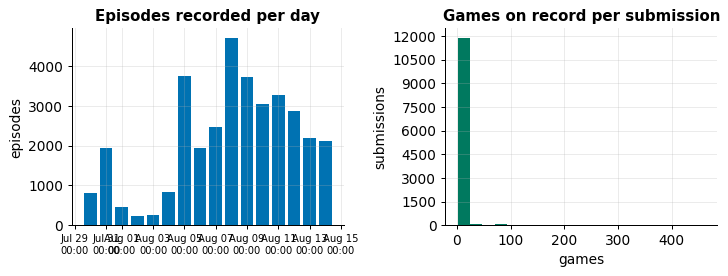

Coverage is **100%** of episodes; the busiest submission has **462** games on record and the median has **2**. Validation runs (1% of rows) are a submission playing itself. Filter them out before comparing strength; the rest of this notebook does.

In [2]:
n_subs = pd.unique(agents.submission_id).size
n_teams = pd.unique(agents.team_id).size
val_share = eps.type.eq("EPISODE_TYPE_VALIDATION").mean()
cover = eps.has_replay.mean()
span_h = (eps.end.max() - eps.end.min()).total_seconds() / 3600

summary = pd.DataFrame({
    "metric": ["episodes", "with full replay", "ladder games", "validation (self-play)",
               "submissions seen", "teams seen", "ladder time covered"],
    "value": [f"{len(eps):,}", f"{len(replay_ids):,} ({cover:.0%})", f"{len(ladder):,}",
              f"{eps.type.eq('EPISODE_TYPE_VALIDATION').sum():,} ({val_share:.0%})",
              f"{n_subs:,}", f"{n_teams:,}",
              f"{span_h:.0f} hours" if span_h <= 72 else f"{span_h / 24:.1f} days"],
})
display(summary.style.hide(axis="index").set_properties(**{"font-size": "13px"})
        .set_table_styles([{"selector": "th", "props": [("font-size", "13px")]}]))

fig, axes = plt.subplots(1, 2, figsize=(8.2, 3.2))
freq1, width1, unit1 = ("1h", 0.032, "hour") if span_h <= 72 else ("1D", 0.8, "day")
by_t = eps.set_index("end").resample(freq1).size()
axes[0].bar(by_t.index, by_t.values, width=width1, color=C_ACC)
axes[0].set_title(f"Episodes recorded per {unit1}"); axes[0].set_ylabel("episodes")
axes[0].xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b %d\n%H:%M"))
axes[0].tick_params(axis="x", labelsize=8)
games = agents.groupby("submission_id").size().sort_values(ascending=False)
axes[1].hist(games.values, bins=min(20, games.nunique()), color=C_TOP)
axes[1].set_title("Games on record per submission")
axes[1].set_xlabel("games"); axes[1].set_ylabel("submissions")
axes[1].yaxis.set_major_locator(plt.matplotlib.ticker.MaxNLocator(integer=True))
plt.tight_layout(); plt.show()

display(Markdown(
    f"Coverage is **{cover:.0%}** of episodes; the busiest submission has **{games.max()}** games "
    f"on record and the median has **{games.median():.0f}**. Validation runs "
    f"({val_share:.0%} of rows) are a submission playing itself. Filter them out before comparing "
    f"strength; the rest of this notebook does."))

# Part II — the ladder

<a id="s2"></a>
## 2. The ladder right now

Winners' final banks across the recorded ladder games, one dot per episode. The spread is the
story of this competition: the same board and the same rules produce farms that differ by an
order of magnitude.

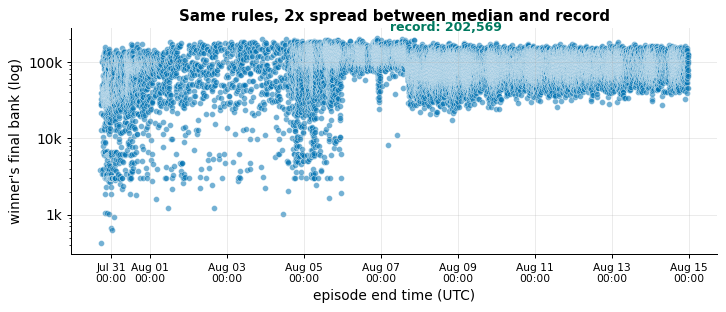

The winner's bank across recorded games: **69,267** at p25, **91,403** median, **136,541** at p90. The record of **202,569** is **2.2×** the median win; section 6 tracks how fast that gap moves.

In [3]:
fig, ax = plt.subplots(figsize=(8.2, 3.6))
ax.scatter(ladder.end, ladder.winner_bank, s=22, alpha=.55, color=C_ACC, edgecolors="white", lw=.4)
rec = ladder.loc[ladder.winner_bank.idxmax()]
ax.annotate(f"record: {fmt(rec.winner_bank)}", xy=(rec.end, rec.winner_bank),
            xytext=(10, 6), textcoords="offset points", fontsize=10, weight="bold", color=C_TOP)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(lambda v, _: f"{v/1000:g}k" if v >= 1000 else f"{v:g}")
ax.set_ylabel("winner's final bank (log)"); ax.set_xlabel("episode end time (UTC)")
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b %d\n%H:%M"))
ax.tick_params(axis="x", labelsize=8.5)
ax.set_title(f"Same rules, {ladder.winner_bank.max() / ladder.winner_bank.median():.0f}x spread "
             "between median and record")
plt.tight_layout(); plt.show()

q = ladder.winner_bank.quantile([.25, .5, .9])
display(Markdown(
    f"The winner's bank across recorded games: **{fmt(q[.25])}** at p25, **{fmt(q[.5])}** median, "
    f"**{fmt(q[.9])}** at p90. The record of **{fmt(rec.winner_bank)}** is "
    f"**{rec.winner_bank / q[.5]:.1f}×** the median win; section 6 tracks how fast that gap moves."))

<a id="s3"></a>
## 3. The shape of a big game

Coin curves of the biggest wins on record against a median game. Top games share a silhouette:
the bank stays near zero deep into the season while everything is reinvested, then compounding
takes over once the farm is built.

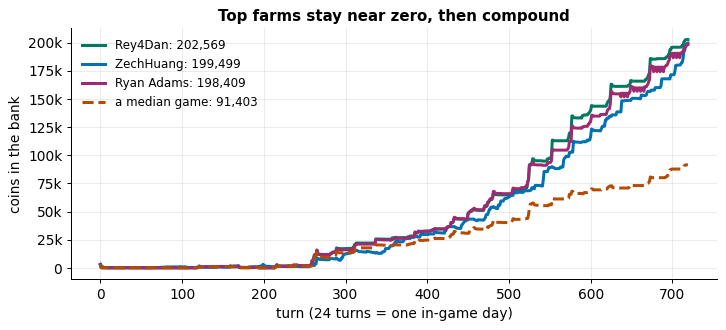

Each top farm crosses a tenth of its final bank on in-game day **12** (top-1), **14** (top-2), **13** (top-3). That crossing, not the last-day sprint, is where the game is decided.

In [4]:
ladder_r = ladder_r.assign(
    winner_sub=np.where(ladder_r.bank_0 >= ladder_r.bank_1, ladder_r.sub_0, ladder_r.sub_1))
top_subs = ladder_r.groupby("winner_sub").winner_bank.max().nlargest(3)

def money_curve(row, seat):
    return [s[0]["observation"]["farms"][seat]["money"]
            for s in load_replay(row.episode_id)["steps"]]

fig, ax = plt.subplots(figsize=(8.2, 3.8))
elbows, seen_teams = {}, set()
for rank, (sub, bank) in enumerate(top_subs.items()):
    row = ladder_r[ladder_r.winner_sub.eq(sub) & ladder_r.winner_bank.eq(bank)].iloc[0]
    seat = 0 if row.bank_0 >= row.bank_1 else 1
    money = money_curve(row, seat)
    team = name_of(row.team_1 if seat else row.team_0)
    if team in seen_teams:                     # same team, another submission
        team = f"{team} (2nd sub)"
    seen_teams.add(team)
    ax.plot(money, lw=2.4, color=[C_TOP, C_ACC, C_LOW][rank],
            label=f"{team}: {fmt(bank)}")
    cross = next((t for t, m in enumerate(money) if m > bank * .1), None)
    if cross is not None:
        elbows[rank + 1] = cross // 24

med_row = ladder_r.loc[(ladder_r.winner_bank - ladder_r.winner_bank.median()).abs().idxmin()]
seat = 0 if med_row.bank_0 >= med_row.bank_1 else 1
ax.plot(money_curve(med_row, seat), lw=2.4, color=C_MID, ls="--",
        label=f"a median game: {fmt(med_row.winner_bank)}")
ax.legend(fontsize=9.5, frameon=False, loc="upper left")
ax.set_xlabel("turn (24 turns = one in-game day)"); ax.set_ylabel("coins in the bank")
ax.yaxis.set_major_formatter(lambda v, _: f"{v/1000:.0f}k" if v else "0")
ax.set_title("Top farms stay near zero, then compound")
plt.tight_layout(); plt.show()

if elbows:
    display(Markdown(
        "Each top farm crosses a tenth of its final bank on in-game day "
        + ", ".join(f"**{d}** (top-{r})" for r, d in elbows.items())
        + ". That crossing, not the last-day sprint, is where the game is decided."))

<a id="s4"></a>
## 4. Strategy fingerprints

Replays store actions, not just scores, so you can compare bots by what they do. Those
fingerprints already sit in `episode_features.csv`, one row per seat for every episode that has
a replay, and section 1 prints how deep that coverage runs, so you rarely need to open a replay
yourself. The cell below is the method behind the crew, land and crop columns; bank shape and
prices get measured in sections 3 and 6. It stays open on purpose: it defines exactly what
`peak_crew` or `first_land_day` mean, and it is where to start if you want to measure something
I did not. Leaders against the middle of the ladder:

In [5]:
def fingerprint(episode_id, seat):
    # Hires are read from the farm state (hires_today), not from submitted HIRE
    # orders — bots keep sending orders the engine rejects once money runs short.
    crops, first_land, peak_crew, hires_by_day = {}, None, 0, {}
    for t, step in enumerate(load_replay(episode_id)["steps"]):
        farm = step[0]["observation"]["farms"][seat]
        day = t // 24
        hires_by_day[day] = max(hires_by_day.get(day, 0), farm["hires_today"])
        peak_crew = max(peak_crew, len(farm["hands"]))
        a = step[seat].get("action") or {}
        for order in (a.get("market") or []):
            if isinstance(order, list) and order and order[0] == "BUY_LAND" and first_land is None:
                first_land = day
        for unit in [a.get("farmer") or []] + list(a.get("hands") or []):
            if isinstance(unit, list) and unit and unit[0] == "PLANT" and len(unit) > 1:
                crops[unit[1]] = crops.get(unit[1], 0) + 1
    return {"hires / day": sum(hires_by_day.values()) / max(1, len(hires_by_day)),  # CSV: total_hires
            "peak crew": peak_crew,
            "first land (day)": first_land, "plants": crops}

In [6]:
# Prefer the shipped table: parsing four more replays here is what pushed the
# kernel over its memory limit once the corpus passed 800 MB.
FEAT = pd.read_csv(f"{BASE}/episode_features.csv")
FEAT_IX = FEAT.set_index(["episode_id", "seat"])
CROPCOLS = [c for c in FEAT.columns if c.startswith("plants_")]

def fingerprint_row(episode_id, seat):
    try:
        r = FEAT_IX.loc[(int(episode_id), int(seat))]
    except KeyError:
        return fingerprint(episode_id, seat)          # fall back to the replay
    plants = {c.replace("plants_", "").upper(): int(r[c]) for c in CROPCOLS if r[c] > 0}
    return {"hires / day": r.total_hires / 30, "peak crew": r.peak_crew,
            "first land (day)": r.first_land_day, "plants": plants}

rows = []
for rank, (sub, bank) in enumerate(top_subs.items()):
    row = ladder_r[ladder_r.winner_sub.eq(sub) & ladder_r.winner_bank.eq(bank)].iloc[0]
    seat = 0 if row.bank_0 >= row.bank_1 else 1
    rows.append({"who": name_of(row.team_1 if seat else row.team_0), "bank": bank,
                 **fingerprint_row(row.episode_id, seat)})
mid_pool = ladder_r[ladder_r.winner_bank.between(*ladder_r.winner_bank.quantile([.45, .55]))]
mid = (mid_pool.iloc[0] if len(mid_pool)
       else ladder_r.loc[(ladder_r.winner_bank - ladder_r.winner_bank.median()).abs().idxmin()])
seat = 0 if mid.bank_0 >= mid.bank_1 else 1
rows.append({"who": f"{name_of(mid.team_1 if seat else mid.team_0)} (mid-ladder)",
             "bank": mid.winner_bank, **fingerprint_row(mid.episode_id, seat)})

fp = pd.DataFrame(rows)
fp["top crop"] = fp.plants.map(lambda d: max(d, key=d.get).title() if d else "—")
fp["tiles planted"] = fp.plants.map(lambda d: sum(d.values()))
display(fp[["who", "bank", "hires / day", "peak crew", "first land (day)",
            "tiles planted", "top crop"]]
        .style.hide(axis="index")
        .format({"bank": "{:,.0f}", "hires / day": "{:.1f}", "first land (day)": "{:.0f}"},
                na_rep="—")
        .set_properties(**{"font-size": "13px"})
        .set_table_styles([{"selector": "th", "props": [("font-size", "13px")]}]))

lead, base = fp.iloc[0], fp.iloc[-1]
crops_top = [c for c in fp["top crop"][:3].tolist() if c != "—"]
uniq_crops = list(dict.fromkeys(crops_top))
lead_land = ("never buys land in this game" if pd.isna(lead["first land (day)"])
             else f"takes land on day **{lead['first land (day)']:.0f}**")
base_land = ("the mid-ladder farm never buys any" if pd.isna(base["first land (day)"])
             else f"the mid-ladder farm waits until day {base['first land (day)']:.0f}")
crop_line = (f"All of the biggest wins lead with {uniq_crops[0]}." if len(uniq_crops) == 1
             else f"The three biggest wins lead with {', '.join(crops_top)}. The winning crop "
                  f"varies; what repeats is the economics around it, not the plant.")
display(Markdown(
    f"One best game per submission, so read it as a sketch rather than a verdict. Still, the "
    f"record holder ({lead['who']}) runs a crew of **{lead['peak crew']:.0f}** against the "
    f"mid-ladder's **{base['peak crew']:.0f}** and {lead_land}; {base_land}. {crop_line}"))

who,bank,hires / day,peak crew,first land (day),tiles planted,top crop
Rey4Dan,"202,569",9.0,14.000000,7,156,Wheat
ZechHuang,"199,499",10.2,12.000000,7,131,Wheat
Ryan Adams,"198,409",9.2,14.000000,7,158,Wheat
Raiden.B (mid-ladder),"87,552",9.2,10.000000,9,143,Wheat


One best game per submission, so read it as a sketch rather than a verdict. Still, the record holder (Rey4Dan) runs a crew of **14** against the mid-ladder's **10** and takes land on day **7**; the mid-ladder farm waits until day 9. All of the biggest wins lead with Wheat.

<a id="s5"></a>
## 5. What actually separates a big bank from a small one

The fingerprints above describe single games. With `episode_features.csv` we can ask the blunter
question across every replayed episode at once: which measurable choices track a large final
bank, and which ones only feel important?

One column is deliberately missing from this chart. `elbow_day` correlates with the bank at 0.8,
but it is derived from the bank itself (the day a farm crosses a tenth of its own final total),
so a weak farm crosses its small tenth early and a strong one crosses late. That is arithmetic,
not strategy, and including it would be the most confident wrong claim in this notebook.

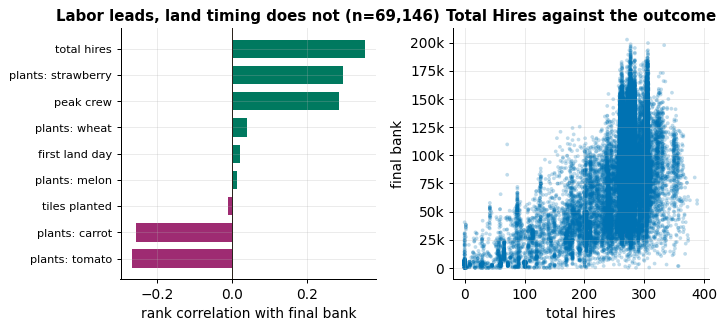

Across **69,146** seats the strongest signal is **total hires** (rank correlation **+0.35**), with crew size close behind. The day a farm first buys land lands at **+0.02**, near zero, even though land is the thing everyone talks about. Among crops, **strawberry** tracks the bank best (**+0.30**). Correlation is not a recipe: heavy hiring may be what winning farms can afford rather than the reason they win. Read it as a list of things worth testing in your own bot, not a ranking of tactics.

In [7]:
feat = pd.read_csv(f"{BASE}/episode_features.csv")
feat = feat[feat.final_money > 0]
CROP_COLS = [c for c in feat.columns
             if c.startswith("plants_") and c[7:].upper() in
             {"CARROT", "MELON", "STRAWBERRY", "TOMATO", "WHEAT"}]
CAND = ["total_hires", "peak_crew", "tiles_planted", "first_land_day"] + CROP_COLS
rho = (feat[CAND + ["final_money"]].corr(method="spearman")["final_money"]
       .drop("final_money").sort_values())

fig, axes = plt.subplots(1, 2, figsize=(8.2, 3.8))
labels = [c.replace("plants_", "plants: ").replace("_", " ") for c in rho.index]
axes[0].barh(range(len(rho)), rho.values, height=.7,
             color=[C_TOP if v > 0 else C_LOW for v in rho.values])
axes[0].set_yticks(range(len(rho)), labels, fontsize=9)
axes[0].axvline(0, color="#2B241D", lw=.8)
axes[0].set_xlabel("rank correlation with final bank")
axes[0].set_title(f"Labor leads, land timing does not (n={len(feat):,})")

top_feat = rho.abs().idxmax()
axes[1].scatter(feat[top_feat], feat.final_money, s=9, alpha=.25, color=C_ACC, edgecolors="none")
axes[1].set_xlabel(top_feat.replace("_", " ")); axes[1].set_ylabel("final bank")
axes[1].yaxis.set_major_formatter(lambda v, _: f"{v/1000:.0f}k" if v else "0")
axes[1].set_title(f"{top_feat.replace('_', ' ').title()} against the outcome")
plt.tight_layout(); plt.show()

best_crop = max(CROP_COLS, key=lambda c: rho.get(c, 0))
display(Markdown(
    f"Across **{len(feat):,}** seats the strongest signal is **{top_feat.replace('_', ' ')}** "
    f"(rank correlation **{rho[top_feat]:+.2f}**), with crew size close behind. The day a farm "
    f"first buys land lands at **{rho['first_land_day']:+.2f}**, near zero, even though land is "
    f"the thing everyone talks about. Among crops, **{best_crop.replace('plants_', '')}** tracks "
    f"the bank best (**{rho[best_crop]:+.2f}**). Correlation is not a recipe: heavy hiring may be "
    f"what winning farms can afford rather than the reason they win. Read it as a list of things "
    f"worth testing in your own bot, not a ranking of tactics."))

<a id="s6"></a>
## 6. The market they create together

Prices are shared between the two players of an episode, and `episode_features.csv` records
every episode's low and high for all nine goods. First the whole corpus, so you can see which
markets actually move; then one game up close, where you can watch them being moved.

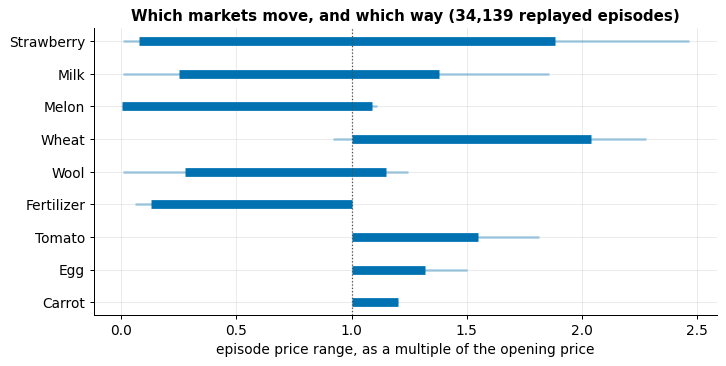

Thick bars span the median episode's low and high; thin lines run from the 10th percentile of the lows to the 90th of the highs. **Strawberry** moves the most: the median episode already rides it from **0.07x** to **1.9x** of its opening price. **Carrot** barely leaves its base. Direction is part of the story too: half of all games dump **Melon** down to **1 coin** against an opening price of **250**. A market that never moves is one nobody trades hard, and that gap is a strategy signal in itself.

In [8]:
feat_p = pd.read_csv(f"{BASE}/episode_features.csv").drop_duplicates("episode_id")
feat_p = feat_p[feat_p.episode_id.isin(ladder_r.episode_id)]
# Cells share one namespace: a bare `rows` here once shadowed section 4's `rows`
# that the personal report reads, so everything local to this cell wears mkt_.
mkt_goods = sorted({c[len("price_"):-len("_min")] for c in feat_p.columns
                    if c.startswith("price_") and c.endswith("_min")})
# The market opens with the same order book every episode, so turn 0 of any replay
# supplies the opening price for every good.
base_replay = load_replay(ladder_r.episode_id.iloc[-1])
mkt_base = {g.lower(): p for g, p in
            base_replay["steps"][0][0]["observation"]["market"]["prices"].items()}
del base_replay; gc.collect()

mkt_rows = []
for g in mkt_goods:
    mkt_lo = feat_p[f"price_{g}_min"] / mkt_base[g]
    mkt_hi = feat_p[f"price_{g}_max"] / mkt_base[g]
    mkt_rows.append({"good": g, "lo_p10": mkt_lo.quantile(.1), "lo_med": mkt_lo.median(),
                     "hi_med": mkt_hi.median(), "hi_p90": mkt_hi.quantile(.9)})
mkt_rng = pd.DataFrame(mkt_rows)
mkt_rng["band"] = mkt_rng.hi_med - mkt_rng.lo_med    # width of the median episode's price ride
mkt_rng = mkt_rng.sort_values("band")

fig, ax = plt.subplots(figsize=(8.2, 4.2))
mkt_y = np.arange(len(mkt_rng))
ax.hlines(mkt_y, mkt_rng.lo_p10, mkt_rng.hi_p90, color=C_ACC, lw=2, alpha=.35)
ax.hlines(mkt_y, mkt_rng.lo_med, mkt_rng.hi_med, color=C_ACC, lw=7)
ax.axvline(1, color="0.3", lw=1, ls=":")
ax.set_yticks(mkt_y, [g.title() for g in mkt_rng.good])
ax.set_xlabel("episode price range, as a multiple of the opening price")
ax.set_title(f"Which markets move, and which way ({len(feat_p):,} replayed episodes)")
plt.tight_layout(); plt.show()

mkt_wild, mkt_calm = mkt_rng.iloc[-1], mkt_rng.iloc[0]
mkt_down = mkt_rng.loc[mkt_rng.lo_med.idxmin()]
# The floor is 1 coin, so a ratio here can read "0.00x"; coins tell it straight.
mkt_down_coins = feat_p[f"price_{mkt_down.good}_min"].median()
mkt_note = ("" if mkt_down.good == mkt_wild.good else
            f" Direction is part of the story too: half of all games dump **{mkt_down.good.title()}** "
            f"down to **{mkt_down_coins:.0f} coin{'s' if mkt_down_coins != 1 else ''}** against an "
            f"opening price of **{mkt_base[mkt_down.good]}**.")
display(Markdown(
    f"Thick bars span the median episode's low and high; thin lines run from the 10th "
    f"percentile of the lows to the 90th of the highs. **{mkt_wild.good.title()}** moves the "
    f"most: the median episode already rides it from **{mkt_wild.lo_med:.2f}x** to "
    f"**{mkt_wild.hi_med:.1f}x** of its opening price. **{mkt_calm.good.title()}** barely "
    f"leaves its base.{mkt_note} A market that never moves is one nobody trades hard, and "
    f"that gap is a strategy signal in itself."))

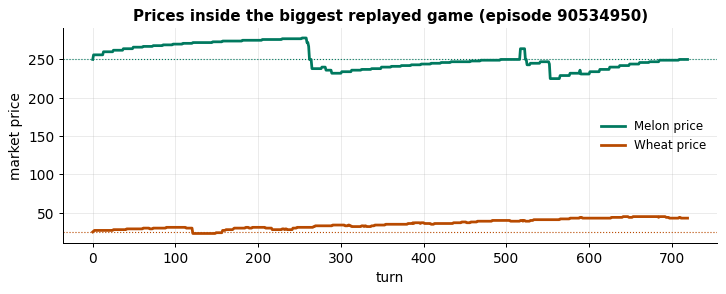

In this game melon starts at **250**, bottoms at **225** and peaks at **278**, a swing of 21% of its base price. Wheat runs **23–45** against a base of **25**. Wheat climbing that far above base usually means animal farms buying feed faster than the town supplies it. Both lines are a strategy log: you can see when a farm dumps and when it trickles.

In [9]:
rec_r = ladder_r.loc[ladder_r.winner_bank.idxmax()]
replay = load_replay(rec_r.episode_id)
prices = {p: [s[0]["observation"]["market"]["prices"][p] for s in replay["steps"]]
          for p in ("MELON", "WHEAT")}
base_price = {p: prices[p][0] for p in prices}

fig, ax = plt.subplots(figsize=(8.2, 3.4))
for p, c in (("MELON", C_TOP), ("WHEAT", C_MID)):
    ax.plot(prices[p], lw=2.2, color=c, label=f"{p.title()} price")
    ax.axhline(base_price[p], color=c, lw=.9, ls=":")
ax.set_xlabel("turn"); ax.set_ylabel("market price")
ax.set_title(f"Prices inside the biggest replayed game (episode {rec_r.episode_id})")
ax.legend(fontsize=9.5, frameon=False); plt.tight_layout(); plt.show()

mel, whe = prices["MELON"], prices["WHEAT"]
wheat_note = (" Wheat climbing that far above base usually means animal farms buying feed faster "
              "than the town supplies it." if max(whe) > base_price["WHEAT"] * 1.4 else "")
display(Markdown(
    f"In this game melon starts at **{base_price['MELON']}**, bottoms at **{min(mel)}** and peaks "
    f"at **{max(mel)}**, a swing of {(max(mel) - min(mel)) / base_price['MELON']:.0%} of its base "
    f"price. Wheat runs **{min(whe)}–{max(whe)}** against a base of **{base_price['WHEAT']}**."
    f"{wheat_note} Both lines are a strategy log: you can see when a farm dumps and when it "
    f"trickles."))

<a id="s7"></a>
## 7. How fast the bar is moving

The number every competitor wants: how much the ladder improves while you sleep. Median
winning bank per time slice, against the record so far. Skip a few days and this is the gap you
come back to. Below the clock: the movers, teams whose rating travelled furthest over the last
seven days of recorded games.

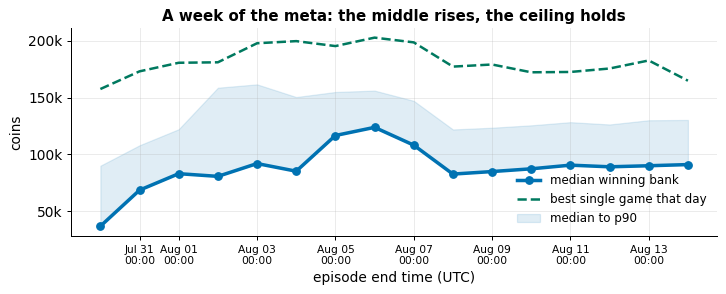

The median winning bank went from **37,002** to **91,112** over **360 hours** of ladder: **+146%**, and the most recent day moved **+1%** against the day before. A bot that stands still slides down the table on its own.

In [10]:
# Prefer the collector's own daily series: it covers the whole history at one row per
# day, while re-deriving it here would re-scan every episode on every run.
DAILY = None
try:
    DAILY = pd.read_csv(f"{BASE}/daily_stats.csv", parse_dates=["date"])
except FileNotFoundError:
    pass

span_d6 = (ladder.end.max() - ladder.end.min()).total_seconds() / 86400
freq6 = "2h" if span_d6 <= 3 else ("6h" if span_d6 <= 10 else ("1D" if span_d6 <= 30 else "3D"))
by_h = (ladder.set_index("end").winner_bank
        .resample(freq6).agg(["median", "max", "count"]).dropna())
solid = by_h[by_h["count"] >= 2]
if len(solid) >= 4:
    by_h = solid
fig, ax = plt.subplots(figsize=(8.2, 3.4))
if DAILY is not None and len(DAILY) >= 3:
    ax.plot(DAILY.date, DAILY.median_winner_bank, lw=2.8, color=C_ACC, marker="o", ms=6,
            label="median winning bank")
    ax.plot(DAILY.date, DAILY.record_bank, lw=2, color=C_TOP, ls="--",
            label="best single game that day")
    ax.fill_between(DAILY.date, DAILY.median_winner_bank, DAILY.p90_winner_bank,
                    color=C_ACC, alpha=.12, label="median to p90")
else:
    ax.plot(by_h.index, by_h["median"], lw=2.6, color=C_ACC,
            marker="o" if len(by_h) <= 48 else None, ms=5, label="median winning bank")
    ax.plot(by_h.index, by_h["max"], lw=2, color=C_TOP, ls="--", label="best game so far")
ax.set_ylabel("coins"); ax.set_xlabel("episode end time (UTC)")
ax.yaxis.set_major_formatter(lambda v, _: f"{v/1000:.0f}k" if v else "0")
ax.set_title("A week of the meta: the middle rises, the ceiling holds")
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b %d\n%H:%M"))
ax.tick_params(axis="x", labelsize=8.5)
ax.legend(fontsize=9.5, frameon=False)
plt.tight_layout(); plt.show()

if DAILY is not None and len(DAILY) >= 3:
    first, last = DAILY.median_winner_bank.iloc[0], DAILY.median_winner_bank.iloc[-1]
    hours = (DAILY.date.iloc[-1] - DAILY.date.iloc[0]).total_seconds() / 3600
else:
    first, last = by_h["median"].iloc[0], by_h["median"].iloc[-1]
    hours = (by_h.index[-1] - by_h.index[0]).total_seconds() / 3600
daily = ladder.set_index("end").winner_bank.resample("1D").median().dropna()
move_txt = f": **{(last / first - 1) * 100:+.0f}%**" if first else ""
day_txt = (f", and the most recent day moved **{(daily.iloc[-1] / daily.iloc[-2] - 1) * 100:+.0f}%** "
           f"against the day before" if len(daily) >= 2 and daily.iloc[-2] > 0 else "")
tail_line = ("A bot that stands still slides down the table on its own." if last >= first else
             "The median can dip when new bots flood in; the record line is the bar that matters.")
display(Markdown(
    f"The median winning bank went from **{fmt(first)}** to **{fmt(last)}** over "
    f"**{hours:.0f} hours** of ladder{move_txt}{day_txt}. {tail_line}"))

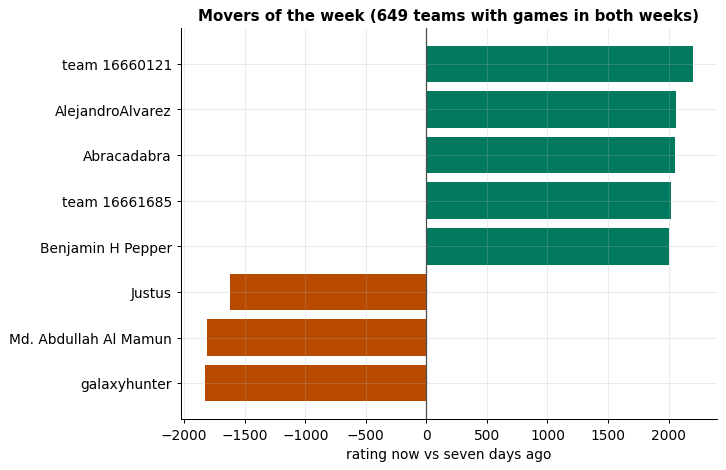

**team 16660121** climbed the furthest: **+2,201** rating over **30** recorded games. The week's best single game banked **182,527**, against an all-time record of **202,569**. One caveat inherited from the collection itself: the crawl favours a few hundred submissions, so a mover outside that set can climb unseen here.

In [11]:
# The week's movers: each team's latest rating against its own rating seven days
# earlier. Thresholds keep one lucky game from reading as a move. All names local
# to this cell wear wk_ (cells share one namespace; see the v27 lesson).
wk_ag = (agents.dropna(subset=["rating_after", "team_id"])
         .merge(ladder[["episode_id", "end"]], on="episode_id")
         .sort_values("end"))
wk_now = wk_ag.end.max()
wk_cur = wk_ag[wk_ag.end > wk_now - pd.Timedelta(days=7)]
wk_old = wk_ag[(wk_ag.end <= wk_now - pd.Timedelta(days=7))
               & (wk_ag.end > wk_now - pd.Timedelta(days=14))]
wk_a = wk_cur.groupby("team_id").agg(games=("rating_after", "size"),
                                     r_new=("rating_after", "last"))
wk_b = wk_old.groupby("team_id").agg(prior=("rating_after", "size"),
                                     r_old=("rating_after", "last"))
wk_m = wk_a.join(wk_b, how="inner")
wk_m = wk_m[(wk_m.games >= 5) & (wk_m.prior >= 3)]
wk_m["delta"] = wk_m.r_new - wk_m.r_old

if len(wk_m) < 4:
    display(Markdown("The corpus does not yet hold two comparable weeks of games for enough "
                     "teams; this chart will appear as the archive grows."))
else:
    wk_show = pd.concat([wk_m.nlargest(5, "delta"), wk_m.nsmallest(3, "delta")])
    wk_show = wk_show[~wk_show.index.duplicated()].sort_values("delta")
    fig, ax = plt.subplots(figsize=(8.2, .52 * len(wk_show) + 1.2))
    wk_c = [C_TOP if d > 0 else C_MID for d in wk_show.delta]
    ax.barh([name_of(t)[:24] for t in wk_show.index], wk_show.delta, color=wk_c)
    ax.axvline(0, color="0.3", lw=1)
    ax.set_xlabel("rating now vs seven days ago")
    ax.set_title(f"Movers of the week ({len(wk_m)} teams with games in both weeks)")
    plt.tight_layout(); plt.show()

    wk_top = wk_m.nlargest(1, "delta").iloc[0]
    wk_rec = ladder[ladder.end > wk_now - pd.Timedelta(days=7)].winner_bank.max()
    wk_all = ladder.winner_bank.max()
    wk_rec_txt = ("which is also the all-time record" if wk_rec == wk_all else
                  f"against an all-time record of **{fmt(wk_all)}**")
    display(Markdown(
        f"**{name_of(wk_top.name)}** climbed the furthest: **{wk_top.delta:+,.0f}** rating over "
        f"**{wk_top.games:.0f}** recorded games. The week's best single game banked "
        f"**{fmt(wk_rec)}**, {wk_rec_txt}. One caveat inherited from the collection itself: "
        f"the crawl favours a few hundred submissions, so a mover outside that set can climb "
        f"unseen here."))

<a id="s8"></a>
## 8. Who beats whom

Ratings compress everything into one number, and that hides the interesting part: matchups don't
have to be transitive. Head-to-head win rates between the busiest teams; read a row as the row
team's share of wins against the column team.

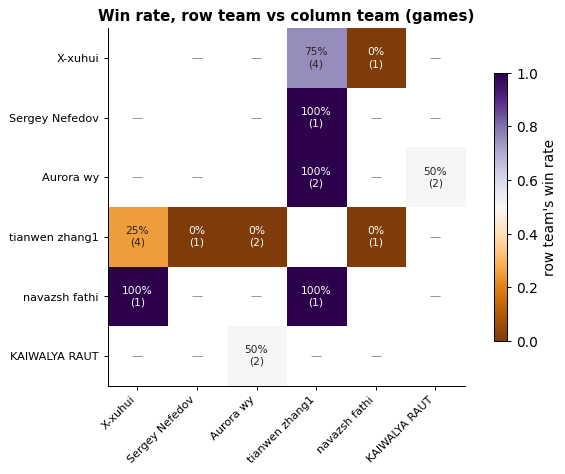

Cells are blank where the pair has not met yet; early ladders are sparse. Clean sweeps so far: **Aurora wy** over **tianwen zhang1** (2 games).

In [12]:
lad = ladder.dropna(subset=["team_0", "team_1"]).copy()
lad["winner_team"] = np.where(lad.bank_0 >= lad.bank_1, lad.team_0, lad.team_1)
busiest = (pd.concat([lad.team_0, lad.team_1]).value_counts().head(6).index.tolist())
mat = pd.DataFrame(np.nan, index=busiest, columns=busiest, dtype=float)
counts = pd.DataFrame(0, index=busiest, columns=busiest, dtype=int)
for a in busiest:
    for b in busiest:
        if a == b:
            continue
        games = lad[((lad.team_0.eq(a) & lad.team_1.eq(b))
                     | (lad.team_0.eq(b) & lad.team_1.eq(a)))]
        if len(games):
            mat.loc[a, b] = games.winner_team.eq(a).mean()
            counts.loc[a, b] = len(games)

labels = [(n if len(n) <= 20 else n[:19] + "…")
          for n in (name_of(t) for t in busiest)]
fig, ax = plt.subplots(figsize=(7.4, 5.4))
im = ax.imshow(mat.values, cmap="PuOr", vmin=0, vmax=1)
ax.set_xticks(range(len(busiest)), labels, rotation=45, ha="right", fontsize=9)
ax.set_yticks(range(len(busiest)), labels, fontsize=9)
for i in range(len(busiest)):
    for j in range(len(busiest)):
        v, n = mat.values[i, j], counts.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0%}\n({n})", ha="center", va="center", fontsize=8.5,
                    color="white" if abs(v - .5) > .3 else "#2B241D")
        elif i != j:
            ax.text(j, i, "—", ha="center", va="center", fontsize=9, color="#8A8073")
ax.set_title("Win rate, row team vs column team (games)")
ax.grid(False); fig.colorbar(im, ax=ax, shrink=.75, label="row team's win rate")
plt.tight_layout(); plt.show()

upsets = [(r, c, mat.loc[r, c]) for r in busiest for c in busiest
          if not np.isnan(mat.loc[r, c]) and mat.loc[r, c] >= .999 and counts.loc[r, c] >= 2]
n_blank = int(np.isnan(mat.values).sum()) - len(busiest)
intro_hh = ("Every pair here has met at least once. " if n_blank == 0 else
            "Cells are blank where the pair has not met yet; early ladders are sparse. ")
display(Markdown(
    intro_hh
    + (f"Clean sweeps so far: "
       + "; ".join(f"**{name_of(r)}** over **{name_of(c)}** ({counts.loc[r, c]} games)"
                   for r, c, _ in upsets[:3]) + "."
       if upsets else "No clean sweeps yet among the busiest teams.")))

<a id="s9"></a>
## 9. How much of this is luck

Same bot, different games: how wide is its spread? This decides how many submissions you need
before believing a result, and whether that one great game was skill or a lucky matchup.

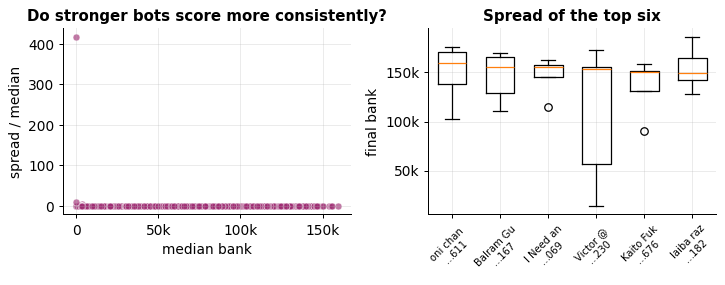

Across submissions with at least four games, the typical spread is **27%** of the median bank (worst: **41764%**). One episode proves little, which is why the ladder keeps playing more of them.

In [13]:
per_sub = (agents[agents.episode_id.isin(ladder.episode_id)]
           .groupby("submission_id").final_bank
           .agg(["count", "median", "std"]).query("count >= 4 and median > 0").dropna())
per_sub["cv"] = per_sub["std"] / per_sub["median"]
fig, axes = plt.subplots(1, 2, figsize=(8.2, 3.3))
axes[0].scatter(per_sub["median"], per_sub["cv"], s=30, alpha=.65, color=C_LOW,
                edgecolors="white", lw=.5)
axes[0].set_xlabel("median bank"); axes[0].set_ylabel("spread / median")
axes[0].xaxis.set_major_formatter(lambda v, _: f"{v/1000:.0f}k" if v else "0")
axes[0].set_title("Do stronger bots score more consistently?")
top_ids = per_sub["median"].nlargest(6).index
lad_agents = agents[agents.episode_id.isin(ladder.episode_id)]
box = [lad_agents[lad_agents.submission_id.eq(s)].final_bank.values for s in top_ids]
axes[1].boxplot(box, widths=.6)
axes[1].set_xticks(range(1, len(top_ids) + 1),
                   [name_of(lad_agents[lad_agents.submission_id.eq(s)].team_id.iloc[0])[:9]
                    + f"\n…{str(s)[-3:]}" for s in top_ids])
axes[1].set_title("Spread of the top six"); axes[1].set_ylabel("final bank")
axes[1].yaxis.set_major_formatter(lambda v, _: f"{v/1000:.0f}k" if v else "0")
axes[1].tick_params(axis="x", rotation=45, labelsize=8)
plt.tight_layout(); plt.show()

display(Markdown(
    f"Across submissions with at least four games, the typical spread is "
    f"**{per_sub.cv.median():.0%}** of the median bank (worst: **{per_sub.cv.max():.0%}**). "
    f"One episode proves little, which is why the ladder keeps playing more of them."))

<a id="s10"></a>
## 10. The openings they share

Two seats with the same stream hash at turn N played byte-identical actions for N straight
turns: a shared opening is an observation, not a similarity threshold. The hashes ship in the
dataset's `stream_hashes.csv`, proposed by
[destbreso in the dataset discussion](https://www.kaggle.com/datasets/georgymamarin/kaggriculture-episodes/discussion/734833).
This section computes itself once the nightly backfill covers the archive; on a partial,
time-ordered slice these rates would measure the backfill, not the meta.

In [14]:
# Self-unlocking: one status line until stream-hash coverage passes the gate.
op_hits = glob.glob(f"{BASE}/stream_hashes.csv")
op_h = pd.read_csv(op_hits[0]) if op_hits else pd.DataFrame(columns=["episode_id", "seat"])
OP_GATE = 0.95
op_cov = op_h.episode_id.nunique() / max(1, len(eps))
if op_cov < OP_GATE:
    display(Markdown(
        f"`stream_hashes.csv` covers **{op_h.episode_id.nunique():,}** of **{len(eps):,}** stored "
        f"episodes so far (**{op_cov:.0%}**). The collector backfills more every night; these "
        f"charts appear on the first scheduled run after coverage passes {OP_GATE:.0%}."))
else:
    op_pref = [24, 100, 200, 400, 719]
    op = op_h[op_h.episode_id.isin(set(ladder_r.episode_id))].merge(
        ladder_r[["episode_id", "team_0", "team_1", "end"]], on="episode_id", how="left")
    op["team"] = np.where(op.seat.eq(0), op.team_0, op.team_1)

    fig, (axL, axR) = plt.subplots(1, 2, figsize=(8.2, 3.4))
    op_share = []
    for op_t in op_pref:
        op_col = op[f"stream_h{op_t}"].dropna()
        op_vc = op_col.value_counts()
        op_share.append((op_col.map(op_vc) > 1).mean())
    axL.plot(op_pref, [s * 100 for s in op_share], marker="o", lw=2.2, color=C_ACC)
    axL.set_xlabel("agree for this many turns"); axL.set_ylabel("% of seats in a shared line")
    axL.set_title("How long the field stays identical")

    op_top = op.stream_h100.value_counts().idxmax()
    op_day = (op.assign(hit=op.stream_h100.eq(op_top))
                .set_index("end").resample("1D").hit.mean().dropna())
    axR.plot(op_day.index, op_day * 100, lw=2.2, color=C_TOP)
    axR.set_ylabel("% of seats that day"); axR.set_title("The biggest turn-100 line, day by day")
    axR.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b %d"))
    axR.tick_params(axis="x", labelsize=8.5)
    plt.tight_layout(); plt.show()

    op_rec = (op.dropna(subset=["stream_h719", "team"])
                .groupby(["team", "stream_h719"]).size())
    op_rec = op_rec[op_rec >= 2]
    op_line = (f"**{op_rec.reset_index().team.nunique():,}** teams replay at least one fixed "
               f"recording: the same team, the same bytes for all 719 turns, in two or more "
               f"games." if len(op_rec) else
               "No team replays a byte-identical full game twice in the covered slice.")
    display(Markdown(
        f"At turn 24, **{op_share[0]:.0%}** of seats share their line with someone else; by "
        f"turn 719 that is **{op_share[-1]:.0%}**. The biggest turn-100 line peaked at "
        f"**{op_day.max():.0%}** of the day's seats. {op_line} The census inherits the "
        f"collection bias: the crawl favours a few hundred submissions, so these shares "
        f"describe the covered corpus, not the whole ladder."))

`stream_hashes.csv` covers **27,364** of **34,581** stored episodes so far (**79%**). The collector backfills more every night; these charts appear on the first scheduled run after coverage passes 95%.

# Part III — make it yours

<a id="s11"></a>
## 11. Your submission against the ladder

The part worth forking. Put your own submission id in the cell below and you get a personal
report: where your best game lands in the whole field, and how your strategy fingerprint
compares with the record holder's. Find your id in `episodes.csv`, or leave the default to see
the record holder's own report.

In [15]:
SUBMISSION_ID = int(top_subs.index[0])   # TWEAK THIS: your submission id from episodes.csv

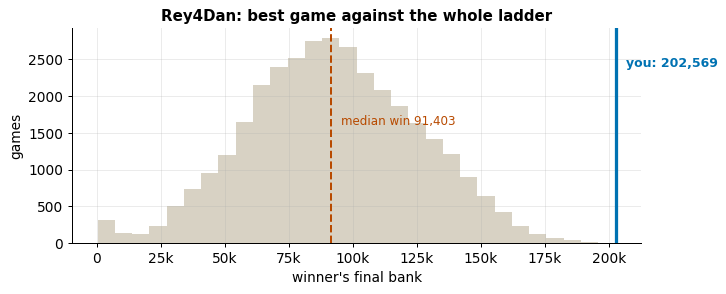

,best bank,games,hires / day,peak crew,first land (day),top crop
Rey4Dan,"202,569",110,9.0,14.000000,7,Wheat
Rey4Dan (record holder),"202,569",110,9.0,14.000000,7,Wheat


**Rey4Dan** has **110** ladder games on record; its best bank of **202,569** beats **100%** of all recorded wins. The row below it is the record holder; the gap in crew size and land timing is usually where the difference starts.

In [16]:
mine = ladder_r[ladder_r.sub_0.eq(SUBMISSION_ID) | ladder_r.sub_1.eq(SUBMISSION_ID)].copy()
mine["my_seat"] = mine.sub_1.eq(SUBMISSION_ID).astype(int)
mine["my_bank"] = np.where(mine.my_seat.eq(1), mine.bank_1, mine.bank_0)
if mine.empty or mine.my_bank.isna().all():
    display(Markdown(
        f"No replayed ladder games for submission **{SUBMISSION_ID}** yet — the crawler usually "
        f"catches up within a day. Check the id in `episodes.csv` or try tomorrow."))
else:
    best = mine.loc[mine.my_bank.idxmax()]
    my_team = name_of(best.team_1 if best.my_seat else best.team_0)
    pct = (ladder.winner_bank < best.my_bank).mean()

    fig, ax = plt.subplots(figsize=(8.2, 3.4))
    ax.hist(ladder.winner_bank, bins=30, color="#D8D2C4")
    ax.axvline(best.my_bank, color=C_ACC, lw=2.6)
    ax.axvline(ladder.winner_bank.median(), color=C_MID, lw=1.6, ls="--")
    ax.annotate(f"you: {fmt(best.my_bank)}", xy=(best.my_bank, ax.get_ylim()[1] * .82),
                xytext=(8, 0), textcoords="offset points", color=C_ACC, weight="bold", fontsize=10)
    ax.annotate(f"median win {fmt(ladder.winner_bank.median())}",
                xy=(ladder.winner_bank.median(), ax.get_ylim()[1] * .55),
                xytext=(8, 0), textcoords="offset points", color=C_MID, fontsize=9.5)
    ax.set_xlabel("winner's final bank"); ax.set_ylabel("games")
    ax.xaxis.set_major_formatter(lambda v, _: f"{v/1000:.0f}k" if v else "0")
    ax.set_title(f"{my_team}: best game against the whole ladder")
    plt.tight_layout(); plt.show()

    rid = int(top_subs.index[0])
    my_fp = fingerprint_row(best.episode_id, int(best.my_seat))
    lead_fp = rows[0]
    top_crop_of = lambda f: (max(f["plants"], key=f["plants"].get).title()
                             if f["plants"] else "—")
    compare = pd.DataFrame([
        {"": my_team, "best bank": best.my_bank, "games": len(mine),
         "hires / day": my_fp["hires / day"], "peak crew": my_fp["peak crew"],
         "first land (day)": my_fp["first land (day)"], "top crop": top_crop_of(my_fp)},
        {"": f"{lead_fp['who']} (record holder)", "best bank": lead_fp["bank"],
         "games": int((ladder_r.sub_0.eq(rid) | ladder_r.sub_1.eq(rid)).sum()),
         "hires / day": lead_fp["hires / day"], "peak crew": lead_fp["peak crew"],
         "first land (day)": lead_fp["first land (day)"], "top crop": top_crop_of(lead_fp)},
    ])
    display(compare.style.hide(axis="index")
            .format({"best bank": "{:,.0f}", "hires / day": "{:.1f}",
                     "first land (day)": "{:.0f}"}, na_rep="—")
            .set_properties(**{"font-size": "13px"})
            .set_table_styles([{"selector": "th", "props": [("font-size", "13px")]}]))

    display(Markdown(
        f"**{my_team}** has **{len(mine)}** ladder games on record; its best bank of "
        f"**{fmt(best.my_bank)}** beats **{pct:.0%}** of all recorded wins. "
        f"The row below it is the record holder; the gap in crew size and land timing is "
        f"usually where the difference starts."))

<a id="s12"></a>
## Before you quote these numbers

The honest edges of this snapshot, so the charts above don't overclaim:

- Fingerprints read one best game per submission: a sketch of a strategy at its peak, not its
  average behavior.
- The corpus is a crawl, not a census. Episodes are discovered through pairings, so a brand-new
  submission can lag behind the ladder by a few hours; section 1 prints the exact replay
  coverage.
- Head-to-head cells stand on a handful of games. The count is printed inside every cell; a 100%
  built on two games is an anecdote, not a verdict.
- Spread estimates use submissions with four or more games each, a modest per-bot sample even
  on a mature ladder; treat them as order-of-magnitude.
- Validation (self-play) episodes are excluded from every strength comparison; section 1 shows
  their share of the raw data.

In [17]:
lead_row = fp.iloc[0]
elbow_txt = ("" if not elbows else
             (f"day **{min(elbows.values())}**"
              if min(elbows.values()) == max(elbows.values())
              else f"day **{min(elbows.values())}–{max(elbows.values())}**"))
land_txt = ("no land purchase at all" if pd.isna(lead_row["first land (day)"])
            else f"land on day **{lead_row['first land (day)']:.0f}**")
crop_txt = (f"and the biggest wins all lead with {uniq_crops[0]}" if len(uniq_crops) == 1
            else "while the biggest wins disagree on which crop to lead with")
display(Markdown(textwrap.dedent(f'''
<a id="s13"></a>
## Takeaways ({AS_OF:%b %d, %Y} snapshot)

1. The ladder's spread is wide: the record win of **{fmt(rec.winner_bank)}** is
   **{rec.winner_bank / q[.5]:.1f}×** the median win of **{fmt(q[.5])}**.
2. Big games share one silhouette: reinvest almost everything, then compound. The leaders cross
   a tenth of their final bank around in-game {elbow_txt}.
3. The record holder's measurable edge is labor and land: a crew of
   **{lead_row['peak crew']:.0f}** and {land_txt}, {crop_txt}.
4. Market prices inside a game are their own strategy log: in the biggest replayed game melon swung
   **{(max(prices["MELON"]) - min(prices["MELON"])) / base_price["MELON"]:.0%}** of its base price
   and wheat ran **{min(prices["WHEAT"])}–{max(prices["WHEAT"])}**.

The [dataset]({"https://www.kaggle.com/datasets/georgymamarin/kaggriculture-episodes"}) and this
notebook both refresh daily, so these numbers re-compute themselves as the meta moves. Build
something on top (a deeper dive, an imitation model, a better fingerprint) and post it; I
feature community work on the dataset page. If there is a metric you want tracked here, say so
in the comments. Replays come from Kaggle's public episode service; credit to the hosts for
keeping it open. For the rules behind these curves, see
[Kaggriculture, Visualized](https://www.kaggle.com/code/georgymamarin/kaggriculture-visualized-what-every-crop-pays).

*— [Georgy Mamarin](https://www.kaggle.com/georgymamarin)*
''')))


<a id="s13"></a>
## Takeaways (Aug 14, 2026 snapshot)

1. The ladder's spread is wide: the record win of **202,569** is
   **2.2×** the median win of **91,403**.
2. Big games share one silhouette: reinvest almost everything, then compound. The leaders cross
   a tenth of their final bank around in-game day **12–14**.
3. The record holder's measurable edge is labor and land: a crew of
   **14** and land on day **7**, and the biggest wins all lead with Wheat.
4. Market prices inside a game are their own strategy log: in the biggest replayed game melon swung
   **21%** of its base price
   and wheat ran **23–45**.

The [dataset](https://www.kaggle.com/datasets/georgymamarin/kaggriculture-episodes) and this
notebook both refresh daily, so these numbers re-compute themselves as the meta moves. Build
something on top (a deeper dive, an imitation model, a better fingerprint) and post it; I
feature community work on the dataset page. If there is a metric you want tracked here, say so
in the comments. Replays come from Kaggle's public episode service; credit to the hosts for
keeping it open. For the rules behind these curves, see
[Kaggriculture, Visualized](https://www.kaggle.com/code/georgymamarin/kaggriculture-visualized-what-every-crop-pays).

*— [Georgy Mamarin](https://www.kaggle.com/georgymamarin)*
